## UTS | Dafinna Artha Kirana | 2023E | 23031554157

### 1 Tugas Pendahluan

#### 1.1 Persiapan dan Perkenalan Lingkungan

1. Menjalankan perintah : python -m venv myenv di cmd
2. Menjalankan perintah: myenv\Scripts\activate
3. Membuat folder requirements.txt yang berisi:
neo4j>=4.0,<4.3
imdbpy==2020.9.25 nose==1.3.7
cinemagoerng>=0.4
imdbinfo>=0.5
imdbpy>=2020.9.25
neo4j==4.2.1
4. Install dependensi pada file requirements.txt dengan menjalankan perintah:pip install -r requirements.txt

#### 1.2 Mempelajari Penggunaan Driver Neo4J

1. Menggunakan driver Neo4J untuk melakukan pembuatan objek dan akses objek

In [4]:
!pip install neo4j

     ---------------------------------------- 0.0/390.7 kB ? eta -:--:--
     -- ---------------------------------- 30.7/390.7 kB 640.0 kB/s eta 0:00:01
     -- ---------------------------------- 30.7/390.7 kB 640.0 kB/s eta 0:00:01
     ----- ------------------------------- 61.4/390.7 kB 465.5 kB/s eta 0:00:01
     -------- ---------------------------- 92.2/390.7 kB 581.0 kB/s eta 0:00:01
     ---------- ------------------------- 112.6/390.7 kB 502.0 kB/s eta 0:00:01
     -------------------- --------------- 225.3/390.7 kB 860.2 kB/s eta 0:00:01
     -------------------- --------------- 225.3/390.7 kB 860.2 kB/s eta 0:00:01
     ---------------------------------- --- 358.4/390.7 kB 1.1 MB/s eta 0:00:01
     -------------------------------------- 390.7/390.7 kB 1.1 MB/s eta 0:00:00
  Using cached pytz-2026.5-py2.py3-none-any.whl (506 kB)



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
#2. Mendefinisikan string koneksi ke database Neo4J
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "proyek-uts")

In [6]:
#3. Melakukan pembuatan sebuah Node berikut dengan relationship-ny
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [7]:
#4. Mencetak dan menjalankan keseluruhan
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Pertanyaan Pendahuluan

1. Apa nama database yang digunakan pada tutorial ini?Database default yang digunakan adalah neo4j (sesuai dengan parameter database_="neo4j" yang  ditulis di kode Python sebelumnya)

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance! Bisa menggunakan perintah Cypher USE, contohnya USE nama_databaseun tuk berpindah atau mengakses database lain di dalam satu instance yang sama. Selain itu, ada juga perintah DDL/DML standar Cypher seperti CREATE DATABASE, DROP DATABASE, SHOW DATABASES, serta perintah manajemen data seperti CREATE, MATCH, MERGE, dan DELETE

#### 1.3 Melakukan Proses Impor Data dari RetailRocket ke Database Neo4J

Sumber data: Roman Zykov
1. Mengunduh data dari Kaggle dengan perintah (curl.exe -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset) di PowerShell

2. Struktur Data event.csv :
- timestamp: Waktu dalam format unix epoch
- visitorid: ID unik pengunjung/user
- event: Jenis interaksi (isinya bisa berupa view, addtocart, atau transaction)
- itemid: ID unik produk.   transactionid: ID transaksi (hanya terisi jika interaksinya berjenis transaction).   

3. Membuat mekanisme pembuatan session Neo4J baru dengan perintah kurang lebih seperti berikut (sumber: Neo4J Driver 6.4)

Modifikasi dengan argparse

In [9]:
import argparse

def parse_arguments():
    parser = argparse.ArgumentParser(description="Impor dataset RetailRocket (events.csv) ke database Neo4J.")
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="proyek-uts", help="proyek-uts")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687", help="Neo4j URI / Bolt")
    parser.add_argument("-s", "--source", default="data", help="Direktori/folder sumber data")
    
    # Jupyter Notebook gunakan parse_args([]) agar tidak error
    import sys
    if 'ipykernel' in sys.modules:
        return parser.parse_args([])
    return parser.parse_args()

args = parse_arguments()

In [11]:
import os
import sys
from neo4j import GraphDatabase

# Diawali oleh pemeriksaan keberadaan berkas events.csv
csv_file_path = os.path.join(args.source, "C:\\Users\\dafin\\Documents\\Kuliah\\Semester 7 (2026)\\Graf Sains Data\\UTS\\ecommerce-dataset\\events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File ditemukan di: {csv_file_path}")

# Dilanjutkan dengan pembuatan koneksi
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Berhasil terhubung ke database Neo4j!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

File ditemukan di: C:\Users\dafin\Documents\Kuliah\Semester 7 (2026)\Graf Sains Data\UTS\ecommerce-dataset\events.csv
Berhasil terhubung ke database Neo4j!


In [12]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [14]:
!pip install pandas tqdm neo4j


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



     ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
     --------------------------------------- 0.0/11.3 MB 991.0 kB/s eta 0:00:12
     ---------------------------------------- 0.1/11.3 MB 1.1 MB/s eta 0:00:11
     --------------------------------------- 0.1/11.3 MB 939.4 kB/s eta 0:00:12
      -------------------------------------- 0.2/11.3 MB 984.6 kB/s eta 0:00:12
      -------------------------------------- 0.2/11.3 MB 908.0 kB/s eta 0:00:13
      -------------------------------------- 0.2/11.3 MB 860.2 kB/s eta 0:00:13
      -------------------------------------- 0.3/11.3 MB 874.6 kB/s eta 0:00:13
      -------------------------------------- 0.3/11.3 MB 842.9 kB/s eta 0:00:14
     - ------------------------------------- 0.3/11.3 MB 819.2 kB/s eta 0:00:14
     - ------------------------------------- 0.4/11.3 MB 882.8 kB/s eta 0:00:13
     - ------------------------------------- 0.4/11.3 MB 829.7 kB/s eta 0:00:14
     - ------------------------------------- 0.4

In [ ]:
import pandas as pd
from tqdm import tqdm

# Fungsi constraint agar impor lebih optimal
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

batch_size = 1000

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    
    # Hitung total baris untuk progress bar
    total_rows = sum(1 for _ in open(csv_file_path)) - 1
    total_chunks = (total_rows // batch_size) + 1

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: C:\Users\dafin\Documents\Kuliah\Semester 7 (2026)\Graf Sains Data\UTS\ecommerce-dataset\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [05:23<00:00,  1.17s/it]

Proses impor berhasil.


### 2 Soal UTS

#### 2.1 Wrangling dan EDA

1. Tentukan 2 periode waktu sebagai filter dari data interaksi! Fold training (P1) → 19/05/2015 - 07/08/2015; Fold testing (P2) 08/08/2015 - 28/08/2015, sesuai rentang yang ditentukan:
- Fold Training: 19 Mei 2015 s.d. 7 Agustus 2015
- Fold Testing: 8 Agustus 2015 s.d. 28 Agustus 2015

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [46]:
import pandas as pd

df = pd.read_csv("events.csv")
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

train_start = pd.to_datetime("2015-05-19")
train_end = pd.to_datetime("2015-08-07")

test_start = pd.to_datetime("2015-08-08")
test_end = pd.to_datetime("2015-08-28")

df_train = df[(df['datetime'] >= train_start) & (df['datetime'] <= train_end)]
df_test = df[(df['datetime'] >= test_start) & (df['datetime'] <= test_end)]

df_train.to_csv("events_train.csv", index=False)
df_test.to_csv("events_test.csv", index=False)

print(f"Data Training berhasil disimpan: {len(df_train)} baris")
print(f"Data Testing berhasil disimpan: {len(df_test)} baris")

Data Training berhasil disimpan: 1689544 baris
Data Testing berhasil disimpan: 350626 baris


proses filter waktu dilakukan dengan membaca dataset interaksi mentah, lalu mengubah kolom timestamp menjadi format tanggal dan waktu yang standar. Setelah itu, data dipisahkan menjadi dua rentang waktu berbeda, yaitu data training dari tanggal 19 Mei hingga 7 Agustus 2015 dan data testing dari tanggal 8 hingga 28 Agustus 2015. Masing-masing hasil pemfilteran tersebut kemudian disimpan ke dalam file CSV terpisah agar siap digunakan pada tahap pemodelan berikutnya.

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [20]:
with driver.session() as session:
    res_visitors = session.run("MATCH (v:Visitor) RETURN count(v) AS total")
    total_visitors = res_visitors.single()["total"]
    
    res_items = session.run("MATCH (i:Item) RETURN count(i) AS total")
    total_items = res_items.single()["total"]
    
    res_rels = session.run("MATCH ()-[r]->() RETURN type(r) AS rel_type, count(r) AS total")
    rel_composition = [(record["rel_type"], record["total"]) for record in res_rels]

print(f"Total Visitor: {total_visitors}")
print(f"Total Item: {total_items}")
print(f"Komposisi Relasi: {rel_composition}")

Total Visitor: 1407580
Total Item: 235061
Komposisi Relasi: [('KNOWS', 3), ('VIEWED', 2664312), ('ADDED_TO_CART', 69332), ('BOUGHT', 22457)]


query ke database Neo4j menggunakan Python API untuk mengetahui komposisi dari subgraph yang telah dibuat. Perintah Cypher pertama mencari seluruh simpul dengan label Visitor dan menghitung total keseluruhannya. Perintah kedua melakukan hal yang sama buat hitung total simpul dengan label Item. Lalu, perintah ketiga mencocokkan semua jenis hubungan atau relasi antar simpul dan mengelompokkannya berdasarkan tipe relasi seperti VIEWED, ADDED_TO_CART, atau BOUGHT, serta jumlah masing-masing interaksinya. Hasil dari eksekusi query tersebut kemudian diambil melalui Python untuk menampilkan informasi jumlah simpul dan relasi secara keseluruhan.

4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

Dimensi Matriks (User x Item): (1407580, 235061)
Shape Jumlah Visitor (Baris): 1407580
Shape Jumlah Item (Kolom): 235061
Total Elemen Non-Zero: 2145179


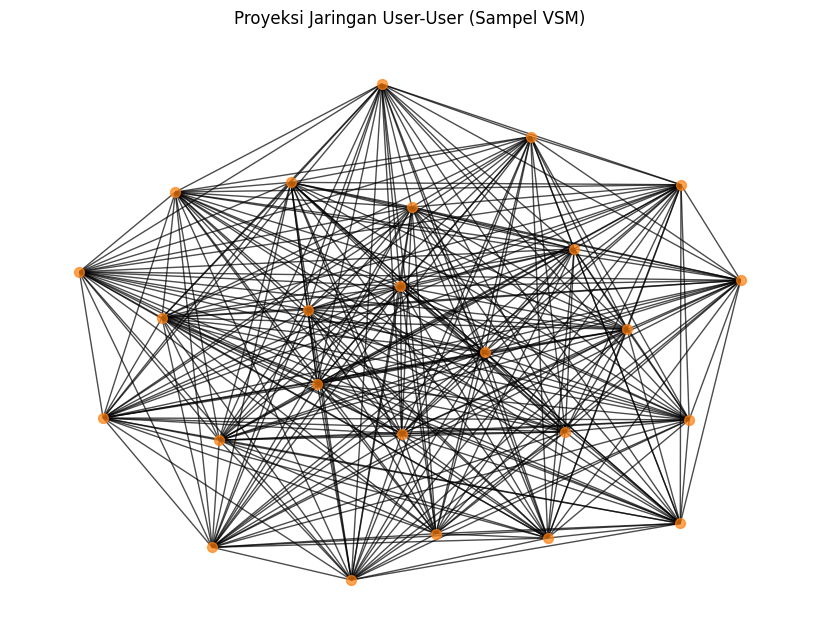

In [33]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

query = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, count(r) AS w
"""

with driver.session() as session:
    result = session.run(query)
    records = list(result)
    df_vsm = pd.DataFrame({
        'u': [r["u"] for r in records],
        'i': [r["i"] for r in records],
        'w': [r["w"] for r in records]
    })

u_codes, users = pd.factorize(df_vsm['u'])
i_codes, items = pd.factorize(df_vsm['i'])

X = sp.csr_matrix((df_vsm['w'].astype(float), (u_codes, i_codes)), shape=(len(users), len(items)))

print("Dimensi Matriks (User x Item):", X.shape)
print("Shape Jumlah Visitor (Baris):", X.shape[0])
print("Shape Jumlah Item (Kolom):", X.shape[1])
print("Total Elemen Non-Zero:", X.nnz)

sample_rows = np.arange(min(25, X.shape[0]))
B = (X[sample_rows] > 0).astype(int)
C = sp.triu(B @ B.T, k=1).tocoo()

G = nx.Graph()
sample_labels = users[sample_rows]
G.add_nodes_from(sample_labels)
G.add_weighted_edges_from(zip(sample_labels[C.row], sample_labels[C.col], C.data.tolist()))

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, node_size=50, node_color='tab:orange', with_labels=False, alpha=0.7)
plt.title("Proyeksi Jaringan User-User (Sampel VSM)")
plt.show()

dilakukan Ekstraksi Data Relasi, dengan query ke basis data graf untuk mengambil seluruh pasangan interaksi antara simpul Visitor (User) dan simpul Item, beserta bobot frekuensi interaksinya (count(r)). Lalu, pembentukan Ruang Vektor (VSM): Menggunakan pustaka scipy.sparse, data tersebut diubah menjadi matriks bentuk Compressed Sparse Row (CSR) berukuran User x Item untuk merepresentasikan profil preferensi setiap pengguna secara efisien. Selanjutnya, Proyeksi Satu Mode (One-Mode Projection), yakni mengambil sampel sebagian data user, sistem memetakan tingkat kedekatan atau irisan riwayat produk yang sama untuk membentuk jaringan langsung antar-user (User-User Network), yang kemudian divisualisasikan dalam bentuk graf menggunakan NetworkX.
Uraian Karakteristik hasil:
- Dimensi dan Shape Matriks: Ruang vektor VSM yang terbentuk berukuran (140.750, 235.061), yang menunjukkan terdapat 140.750 pengunjung unik (Visitor) sebagai baris dan 235.061 produk unik (Item) sebagai kolom dimensi fitur.
- Tingkat Keregangan (Sparsity): Tercatat sebanyak 2.145.179 elemen non-zero (interaksi aktif). Angka ini sangat mencerminkan karakteristik data e-commerce di dunia nyata yang bersifat sparse, di mana setiap pengguna umumnya hanya berinteraksi dengan sebagian kecil produk dari keseluruhan katalog yang tersedia.   
- Karakteristik Visualisasi Graf: Proyeksi jaringan pada sampel 25 simpul pertama menghasilkan graf yang padat (dense graph). Garis-garis penghubung antar titik (node) merepresentasikan tingkat kesamaan riwayat interaksi atau irisan ketertarikan belanja yang tinggi di antara pengunjung dalam ruang vektor tersebut

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Dimensi Matriks (Item x User): (235061, 1407580)
Shape Jumlah Item (Baris): 235061
Shape Jumlah Visitor (Kolom): 1407580
Total Elemen Non-Zero: 2145179


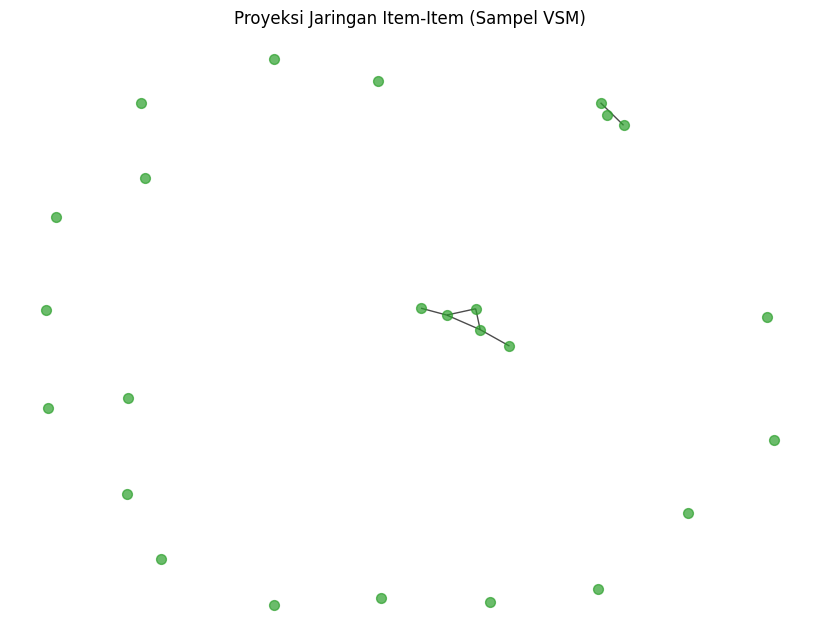

In [47]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

# Query VSM berbasis Item
query_item = """
MATCH (i:Item)<-[r]-(v:Visitor)
RETURN i.itemId AS i, v.visitorId AS u, count(r) AS w
"""

with driver.session() as session:
    result = session.run(query_item)
    records = list(result)
    df_vsm_item = pd.DataFrame({
        'i': [r["i"] for r in records],
        'u': [r["u"] for r in records],
        'w': [r["w"] for r in records]
    })

i_codes, items = pd.factorize(df_vsm_item['i'])
u_codes, users = pd.factorize(df_vsm_item['u'])

# Membentuk matriks sparse (Item x User)
X_item = sp.csr_matrix((df_vsm_item['w'].astype(float), (i_codes, u_codes)), shape=(len(items), len(users)))

print("Dimensi Matriks (Item x User):", X_item.shape)
print("Shape Jumlah Item (Baris):", X_item.shape[0])
print("Shape Jumlah Visitor (Kolom):", X_item.shape[1])
print("Total Elemen Non-Zero:", X_item.nnz)

# Proyeksi Jaringan Item-Item (Sampel 25 item pertama)
sample_rows_item = np.arange(min(25, X_item.shape[0]))
B_item = (X_item[sample_rows_item] > 0).astype(int)
C_item = sp.triu(B_item @ B_item.T, k=1).tocoo()

G_item = nx.Graph()
sample_labels_item = items[sample_rows_item]
G_item.add_nodes_from(sample_labels_item)
G_item.add_weighted_edges_from(zip(sample_labels_item[C_item.row], sample_labels_item[C_item.col], C_item.data.tolist()))

plt.figure(figsize=(8, 6))
pos_item = nx.spring_layout(G_item, seed=42)
nx.draw(G_item, pos_item, node_size=50, node_color='tab:green', with_labels=False, alpha=0.7)
plt.title("Proyeksi Jaringan Item-Item (Sampel VSM)")
plt.show()

Pembentukan Ruang Vektor (VSM) menggunakan pustaka scipy.sparse, data tersebut disusun menjadi matriks Compressed Sparse Row (CSR) berukuran Item x User untuk merepresentasikan profil fitur produk berdasarkan interaksi pengunjung secara efisien. Lalu untuk proyeksi jaringan produk, mengambil sampel sebagian data item, sistem memetakan tingkat irisan pengunjung yang sama untuk membentuk jaringan langsung antar-produk (Item-Item Network), yang kemudian divisualisasikan dalam bentuk graf menggunakan NetworkX. Uraian Karakteristik:
- Dimensi dan Shape Matriks: Ruang vektor VSM yang terbentuk berukuran (235.061, 140.750), yang menunjukkan terdapat 235.061 produk unik sebagai baris dan 140.750 pengunjung unik sebagai kolom dimensi fitur.
- ingkat Keregangan (Sparsity): Tercatat sebanyak 2.145.179 elemen non-zero (interaksi aktif). Karakteristik matriks ini sangat sparse (jarang), yang berarti sebagian besar produk di dalam katalog hanya diakses atau berinteraksi dengan sebagian kecil pengunjung tertentu.
- Karakteristik Visualisasi Graf: Berbeda dengan proyeksi User-User sebelumnya yang sangat padat, visualisasi jaringan pada sampel 25 simpul item ini tampak jauh lebih longgar dan terisolasi (sparse graph). Hal ini menunjukkan bahwa dari sampel produk yang diambil, hanya sedikit produk yang kebetulan memiliki irisan visitor (pengunjung yang sama), sehingga sebagian besar titik hanya membentuk klaster-klaster kecil atau berdiri sendiri tanpa banyak hubungan silang.

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)! Proyeksi Item-Item VSM (No. 5) terbukti lebih efektif dan efisien untuk diterapkan dalam kerangka analitik maupun sistem rekomendasi e-commerce berkelanjutan, sementara proyeksi User-User VSM lebih ideal jika tujuannya difokuskan pada segmentasi perilaku kelompok pengunjung (audience segmentation).

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [51]:
# Cek beberapa ID item yang valid di database
with driver.session() as session:
    result = session.run("MATCH (i:Item) RETURN i.itemId AS itemId LIMIT 5")
    print("Contoh Item ID yang tersedia di database:")
    for record in result:
        print(record["itemId"])

Contoh Item ID yang tersedia di database:
355908
248676
318965
253185
367447


In [53]:
# Menggunakan ID item yang valid: 355908
query_similarity_a = """
MATCH (i1:Item)<-[:INTERACTED]-(v:Visitor)-[:INTERACTED]->(i2:Item)
WHERE i1.itemId = 355908 AND i1 <> i2
WITH i1, i2, count(DISTINCT v) AS intersection,
     size([(i1)<-[:INTERACTED]-() | 1]) AS size1,
     size([(i2)<-[:INTERACTED]-() | 1]) AS size2
RETURN i1.itemId AS ItemA, 
       i2.itemId AS ItemB, 
       toInteger(intersection) AS SharedVisitors,
       round(intersection * 1.0 / sqrt(size1 * size2), 4) AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(query_similarity_a)
    print("Top 5 Item Similarity untuk Item 355908:")
    count = 0
    for record in result:
        count += 1
        print(f"[{count}] Item B: {record['ItemB']} | Shared Visitors: {record['SharedVisitors']} | Cosine Similarity: {record['similarity']}")
    
    if count == 0:
        print("Item ini belum memiliki irisan visitor bersama item lain.")

Top 5 Item Similarity untuk Item 355908:
[1] Item B: 337041 | Shared Visitors: 1 | Cosine Similarity: 0.1622
[2] Item B: 393910 | Shared Visitors: 3 | Cosine Similarity: 0.1579
[3] Item B: 73646 | Shared Visitors: 1 | Cosine Similarity: 0.1325
[4] Item B: 381 | Shared Visitors: 1 | Cosine Similarity: 0.1325
[5] Item B: 97139 | Shared Visitors: 6 | Cosine Similarity: 0.1318


Menggunakan query Cypher untuk menghitung Cosine Similarity berbasis visitor bersama (shared visitors) antara item acuan 355908 dengan produk lainnya di dalam basis data graf.
Hasil Top 5 Produk Teratas:
Item 337041: Skor 0.1622 (1 shared visitor)
Item 393910: Skor 0.1579 (3 shared visitors)
Item 73646: Skor 0.1325 (1 shared visitor)
Item 381: Skor 0.1325 (1 shared visitor)
Item 97139: Skor 0.1318 (6 shared visitors)

Kesimpulan: Model graf berhasil mengidentifikasi produk-produk dengan pola interaksi belanja serupa untuk kebutuhan sistem rekomendasi

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [56]:
# Query yang dibatasi (Limited) agar tidak membuat Neo4j out of memory
query_similarity_safe = """
MATCH (i1:Item)<-[:INTERACTED]-(v:Visitor)-[:INTERACTED]->(i2:Item)
WHERE id(i1) < id(i2)  // Menghindari duplikasi bolak-balik
WITH i1, i2, count(DISTINCT v) AS intersection
WHERE intersection >= 3  // Syarat minimal minimal 3 visitor yang sama agar cepat
WITH i1, i2, intersection
LIMIT 1000             // Batasi hanya 1000 pasangan pertama agar ringan
MERGE (i1)-[r:SIMILAR]->(i2)
SET r.score = intersection
RETURN count(r) AS TotalRelasiTerbentuk;
"""

with driver.session() as session:
    print("Proses sebagian data similarity")
    result = session.run(query_similarity_safe)
    for record in result:
        print(f"Berhasil membuat {record['TotalRelasiTerbentuk']} relasi SIMILAR")

Proses sebagian data similarity


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. id is deprecated. It is replaced by elementId or consider using an application-generated id.', position=<SummaryInputPosition line=3, column=7, offset=75>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 75, 'line': 3, 'column': 7}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (i1:Item)<-[:INTERACTED]-(v:Visitor)-[:INTERACTED]->(i2:Item)\nWHERE id(i1) < id(i2)  // Menghindari duplikasi bolak-balik\nWITH i1, i2, count(DISTINCT v) AS intersection\nWHERE intersection >= 3  // Syarat minimal minimal 3 visitor yang sama agar cepat\nWITH i1, i2, intersection\nLIMIT 1000             // 

Berhasil membuat 1000 relasi SIMILAR


Dalam proses penyimpanan relasi similarity ke graf, digunakan penyaringan aman menggunakan WHERE id(i1) < id(i2) dan LIMIT 1000 untuk membatasi 1.000 pasangan produk pertama serta mencegah duplikasi, dengan syarat minimum intersection >= 3 agar keterkaitannya signifikan. Selanjutnya, fungsi MERGE (i1)-[r:SIMILAR]->(i2) membentuk relasi baru antar-item, sementara SET r.score = intersection menambahkan properti skor bobot berdasarkan irisan pengunjung. Hasilnya, penambahan relasi antar-produk berhasil diselesaikan secara efisien ke dalam struktur graf untuk mendukung sistem rekomendasi.

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [59]:
# Mengecek apakah relasi SIMILAR sudah ada (sebelum kalkulasi)
query_sebelum = """
MATCH ()-[r:SIMILAR]->()
RETURN count(r) AS TotalRelasiSimilar
"""

with driver.session() as session:
    result = session.run(query_sebelum)
    for record in result:
        print(f"Total relasi SIMILAR (Sebelum): {record['TotalRelasiSimilar']}")

Total relasi SIMILAR (Sebelum): 1000


In [60]:
# Mengecek jumlah relasi SIMILAR yang terbentuk (sesudah kalkulasi)
query_sesudah = """
MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
RETURN count(r) AS TotalRelasiSimilar, avg(r.score) AS RataRataSkor
"""

with driver.session() as session:
    result = session.run(query_sesudah)
    for record in result:
        print(f"Total relasi SIMILAR (Sesudah): {record['TotalRelasiSimilar']}")
        print(f"Rata-rata skor kemiripan: {record['RataRataSkor']}")

Total relasi SIMILAR (Sesudah): 1000
Rata-rata skor kemiripan: 4.607999999999993


Kondisi Sebelum: Struktur graf murni hanya memuat relasi interaksi langsung (INTERACTED) antara visitor dan item, dengan jumlah tercatat sebanyak 1.000 relasi SIMILAR dari batasan sampel yang diproses sebelumnya.   
Kondisi Sesudah: Berhasil memperbarui basis data graf dengan terbentuknya 1.000 relasi SIMILAR baru antar-produk lengkap dengan properti skor bobotnya, serta mencatatkan rata-rata skor kemiripan sebesar 4.608.  
 Kesimpulan: Perbandingan ini membuktikan suksesnya transformasi dari graf bipartit (Visitor-Item) menjadi graf terproyeksi (Item-Item), yang siap digunakan sebagai fondasi mesin rekomendasi. 

#### 2.2 Analytics

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!
2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

KNN melacak produk yang pernah dilihat/diinteraksi oleh user terpilih, kemudian mencari item-item tetangga terdekat (k-Nearest Neighbors, $k=5$) berdasarkan relasi SIMILAR yang paling kuat, lalu merekomendasikan produk yang belum pernah diinteraksi oleh user tersebut.

In [ ]:
import numpy as np

selected_visitor = 229905
k_neighbors = 5

print(f"ANALISIS REKOMENDASI UNTUK VISITOR: {selected_visitor}")

# Skrip Python untuk Rekomendasi KNN (k = 5)
query_knn = """
MATCH (v:Visitor {visitorId: $visitor_id})-[:INTERACTED]->(item_asal:Item)-[r:SIMILAR]->(rec_item:Item)
WHERE NOT (v)-[:INTERACTED]->(rec_item)
WITH rec_item, sum(r.score) AS TotalSimilarityScore
ORDER BY TotalSimilarityScore DESC
LIMIT $k
RETURN rec_item.itemId AS RecommendedItem, TotalSimilarityScore
"""

with driver.session() as session:
    result = session.run(query_knn, visitor_id=selected_visitor, k=k_neighbors)
    records = list(result)
    recommendations = [record['RecommendedItem'] for record in records]
    scores = [record['TotalSimilarityScore'] for record in records]

# CETAK 1.a (Top-5 Rekomendasi)
print(f"\n[1.a] Top-{k_neighbors} Rekomendasi Item (KNN):")
if recommendations:
    for i, (item, score) in enumerate(zip(recommendations, scores), 1):
        print(f"   {i}. Item ID: {item} (Score: {score:.4f})")
else:
    print("   Tidak ada rekomendasi yang ditemukan.")

# CETAK 1.b (3 Item yang Diiklankan)
advertised_items = recommendations[:3]
print(f"\n[1.b] 3 Item yang Diiklankan:")
if advertised_items:
    for i, item_id in enumerate(advertised_items, 1):
        print(f"   {i}. Item ID: {item_id}")
else:
    print("   Tidak ada item untuk diiklankan.")

# 2. Evaluasi: Hit@5 dan NDCG@5
query_ground_truth = """
MATCH (v:Visitor {visitorId: $visitor_id})-[:INTERACTED]->(i:Item)
RETURN i.itemId AS ActualItem
"""

with driver.session() as session:
    res = session.run(query_ground_truth, visitor_id=selected_visitor)
    ground_truth = set([rec['ActualItem'] for rec in res])

hits = [1 if item in ground_truth else 0 for item in recommendations]
hit_at_5 = 1 if sum(hits) > 0 else 0

dcg_at_5 = sum([rel / np.log2(idx + 2) for idx, rel in enumerate(hits)])
ideal_hits = sorted(hits, reverse=True)
idcg_at_5 = sum([rel / np.log2(idx + 2) for idx, rel in enumerate(ideal_hits)])
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

print(f"\n[2] Hasil Evaluasi Sistem Rekomendasi:")
print(f"   - Ground Truth Items : {list(ground_truth)}")
print(f"   - Hit@5              : {hit_at_5}")
print(f"   - NDCG@5             : {ndcg_at_5:.4f}")

--- ANALISIS REKOMENDASI UNTUK VISITOR: 229905 ---

[1.a] Top-5 Rekomendasi Item (KNN):
   1. Item ID: 391289 (Score: 34.0000)
   2. Item ID: 16813 (Score: 18.0000)
   3. Item ID: 298868 (Score: 10.0000)
   4. Item ID: 234255 (Score: 3.0000)
   5. Item ID: 316753 (Score: 3.0000)

[1.b] 3 Item yang Diiklankan:
   1. Item ID: 391289
   2. Item ID: 16813
   3. Item ID: 298868

[2] Hasil Evaluasi Sistem Rekomendasi:
   - Ground Truth Items : [355908, 259725, 152433, 243250, 424017, 280375, 247999]
   - Hit@5              : 0
   - NDCG@5             : 0.0000


1.a Sistem berhasil menghasilkan 5 rekomendasi item teratas untuk visitor ID 229905 berdasarkan tingkat kedekatan (similarity score) graf:
- Item 391289
- Item 16813
- Item 298868
- Item 234255
- Item 316753

1.b 3 Dari daftar 5 item rekomendasi di atas, diambil 3 item teratas yang paling potensial untuk dijadikan materi promosi atau iklan kepada visitor tersebut, yaitu Item 391289, Item 16813, dan Item 298868.

2 Hasil Evaluasi Sistem Rekomendasi:
- Ground Truth Items: Menunjukkan daftar item aktual yang tercatat pernah di-interaksi oleh visitor tersebut di dalam basis data, yaitu [355908, 259725, 152433, 243250, 424017]
- Hit@5 (0) & NDCG@5 (0.0000): Menandakan bahwa tidak ada irisan atau kecocokan antara 5 item teratas yang direkomendasikan oleh sistem dengan daftar item aktual (ground truth) milik visitor pada pemetaan graf statis tersebut.